In [2]:
# Cat vs. dog classification

# steps
# Step 1: Load and Preprocess Dog Images
    # 1. Initialize containers
    # 2. Loop through 500 images:
    # 3. Convert to RGB:
    # 4. Resize to 64×64:
    # 5. Convert to a NumPy array:
    # 6. Append to the list:
# Step 2: Load and Preprocess Cat Images
    # 1. Initialize containers
    # 2. Loop through 500 images:
    # 3. Convert to RGB:
    # 4. Resize to 64×64:
    # 5. Convert to a NumPy array:
    # 6. Append to the list:
# Step 3: Combine Dogs and Cats into One Dataset
    # 1. Concatenate the image lists: dog_array + cat_array
    # 2. Convert to a NumPy array: np.array(...)
    # 3. Build the label array: dog_output + cat_output
    # 4. Reshape: X.reshape(-1, 64, 64, 3)
    # 5. Print the shapes:
# Step 4: Build the CNN Model
    # 1. Feature extraction (Conv + Pool blocks):
    # 2. Flatten: 
    # 3. Classification (Dense layers):
    # 4. Softmax output:
# Step 5: Compile the Model
# Step 6: Train the Model

In [2]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as pl
from tensorflow import keras

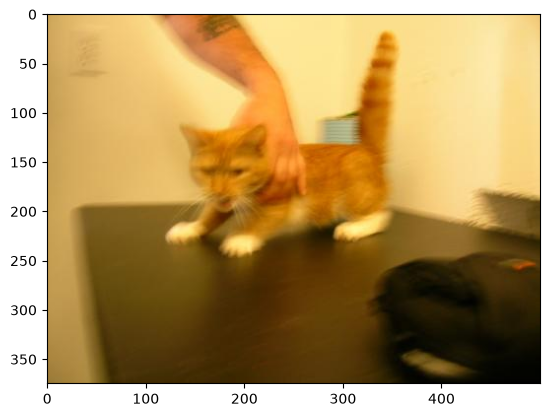

(375, 500, 3)

In [10]:
img = Image.open("PetImages/Cat/0.jpg")
pl.imshow(img)
pl.show()
np.shape(img)

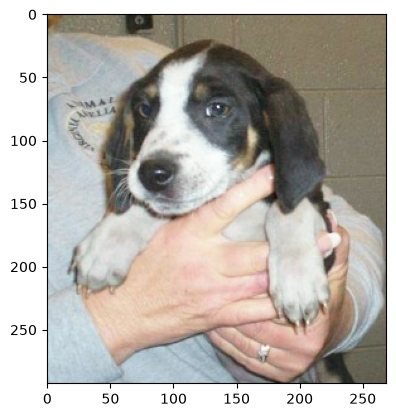

In [4]:
img = Image.open("PetImages/Dog/10.jpg")
pl.imshow(img)
pl.show()

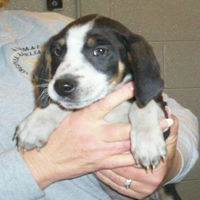

In [5]:
img_resized = img.resize((200,200))
img_resized

In [11]:
# Step 1: Load and Preprocess Dog Images

dog_array = []
dog_output = [0]*500
for i in range(500):
    img = Image.open(f"PetImages/Dog/{i}.jpg").convert('RGB')
    img = img.resize((64,64))
    arr = np.array(img)
    dog_array.append(arr)

# Step 2: Load and Preprocess Cat Images

cat_array = []
cat_output = [1]*500
for i in range(500):
    img = Image.open(f"PetImages/Cat/{i}.jpg").convert('RGB')
    img = img.resize((64,64))
    arr = np.array(img)
    cat_array.append(arr)

# Step 3: Combine Dogs and Cats into One Dataset

X = np.array(dog_array + cat_array)
y = np.array(dog_output + cat_output)
X = X.reshape(-1,64,64,3)
print(X.shape, y.shape)

(1000, 64, 64, 3) (1000,)


In [13]:
# Step 4: Build the CNN Model

model = keras.Sequential([
    keras.layers.Input((64,64,3)),

    # Extract visual features
    keras.layers.Conv2D(16,kernel_size=(3,3), activation="relu"),
    keras.layers.MaxPool2D(pool_size=(2,2)),

    keras.layers.Conv2D(8,kernel_size=(3,3), activation="relu"),
    keras.layers.MaxPool2D(pool_size=(2,2)),

    # Convert features into a vector
    keras.layers.Flatten(),

    # Learn classification patterns
    keras.layers.Dense(32,activation='relu'), # input layer
    
    keras.layers.Dense(16,activation='relu'), # hidden layer
    keras.layers.Dense(8,activation='relu'), # hidden layer
    
    keras.layers.Dense(2,activation='softmax'), # output layer
    
])

In [14]:
# Step 5: Compile the Model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [15]:
# Step 6: Train the Model
model.fit(X,y,epochs=10)

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.4950 - loss: 2.6272
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5310 - loss: 0.6917
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.5580 - loss: 0.6821
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.5920 - loss: 0.6599
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6290 - loss: 0.6360
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6740 - loss: 0.5918
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7480 - loss: 0.5327
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7950 - loss: 0.4710
Epoch 9/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8170 - loss: 0.4001
Epoch 10/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.8320 - loss: 0.3763
